# 04 — Envelope theo miền thời gian và miền tần số

Notebook dùng để **quan sát riêng từng phương pháp envelope**, không chồng nhiều đường envelope lên cùng một trục.

- Mỗi phương pháp có **một figure riêng** (không vẽ chồng các envelope của nhiều phương pháp).
- Trong từng subplot, tín hiệu sau BPF được vẽ **màu xám rất nhạt ở nền**; envelope của phương pháp đang xét được vẽ nổi bật phía trên.
- Các phương pháp dùng chung BPF 2300–3800 Hz, LPF 750 Hz và `remove_dc=False`, khớp notebook benchmark 06 và các số liệu fidelity.
- `hilbert_block` dùng FFT từng block 2048 mẫu, không chồng lấn; phần FFT được chạy với `float32`. Trong `dsp.py` hiện tại, đoạn cuối nếu ngắn hơn 2048 được FFT với đúng độ dài còn lại. Cần đồng bộ chính sách xử lý block cuối này với firmware C trước khi tuyên bố PC–MCU tương đương. BPF/LPF trong mô phỏng Python vẫn chạy theo implementation của `dsp.py`.
- Phổ envelope toàn file chỉ dùng để quan sát; đặc trưng MLP vẫn được tính trên cửa sổ 2048 mẫu raw tương ứng với envelope decimate ×2.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import io_utils, dsp, config as cfg
from src.pipeline import pick_file

In [2]:
OUTPUT_DIR = Path("./outputs")
TABLES_DIR = OUTPUT_DIR / "tables"
FIGURES_DIR = OUTPUT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

manifest_path = TABLES_DIR / "manifest_clean.csv"
if not manifest_path.exists():
    raise FileNotFoundError(
        f"Không tìm thấy {manifest_path}. Hãy chạy notebook tạo manifest trước."
    )
manifest = pd.read_csv(manifest_path)

FS = float(cfg.SCOPE["sampling_rate_hz"])       # fs chuẩn hóa đầu vào DSP: 12 kHz
BAND_HZ = tuple(cfg.RESONANCE_BAND_HZ)          # 2300–3800 Hz
LP_CUTOFF_HZ = float(cfg.LP_CUTOFF_HZ)          # 750 Hz
BPF_ORDER = dsp.BENCHMARK_BANDPASS_ORDER
LOWPASS_ORDER = dsp.BENCHMARK_LOWPASS_ORDER
WARMUP = int(cfg.WARMUP_SAMPLES)

# Kích thước FFT Hilbert Block phải trùng cửa sổ đặc trưng của dự án.
WINDOW_RAW = int(cfg.WINDOW_SIZE_RAW)
STRIDE_RAW = int(cfg.STRIDE_RAW)
HILBERT_BLOCK_SIZE = int(getattr(dsp, "HILBERT_BLOCK_SIZE", WINDOW_RAW))
if HILBERT_BLOCK_SIZE != WINDOW_RAW:
    raise ValueError(
        f"HILBERT_BLOCK_SIZE={HILBERT_BLOCK_SIZE} phải bằng "
        f"WINDOW_SIZE_RAW={WINDOW_RAW} để đối chiếu đúng cấu hình."
    )

# Mỗi method có kwargs riêng; chỉ Hilbert Block cần mô phỏng phần FFT float32.
ENVELOPE_METHODS = [
    {
        "name": "Hybrid",
        "key": "hybrid",
        "color": "tab:green",
        "kwargs": {},
    },
    {
        "name": "FFT Hilbert offline (tham chiếu)",
        "key": "hilbert_offline",
        "color": "tab:orange",
        "kwargs": {},
    },
    {
        "name": f"Hilbert Block (N={HILBERT_BLOCK_SIZE}, float32)",
        "key": "hilbert_block",
        "color": "tab:blue",
        "kwargs": {
            "block_size": HILBERT_BLOCK_SIZE,
            "float32": True,
            "align_delay": True,
        },
    },
]

# Chọn file minh họa: một file cho mỗi nhóm lỗi, cùng mức tải.
LABELS_TO_PLOT = ["Normal", "IR", "OR", "B"]
LOAD_HP = 1
DIAMETER_MILS = 14             # chỉ áp dụng cho IR/OR/B
SEGMENT_SECONDS = 0.05         # đoạn thời gian hiển thị sau warm-up


In [3]:
def load_case(label):
    diameter = None if label == "Normal" else DIAMETER_MILS
    file_path = pick_file(
        manifest,
        label=label,
        load_hp=LOAD_HP,
        diameter_mils=diameter,
    )
    row = manifest.loc[manifest["file_path"] == file_path].iloc[0]

    x = np.asarray(
        io_utils.load_de_signal_resampled(
            Path(file_path),
            float(row["resolved_sample_rate_hz"]),
            FS,
        ),
        dtype=np.float64,
    ).reshape(-1)

    if x.size <= WARMUP + 10:
        raise ValueError(
            f"{Path(file_path).name}: tín hiệu quá ngắn sau warm-up."
        )
    if not np.isfinite(x).all():
        raise ValueError(f"{Path(file_path).name}: tín hiệu có NaN/Inf.")

    return file_path, row, x


def extract_envelopes(x):
    """Dùng cùng BPF/LPF và remove_dc=False như benchmark notebook 06."""
    envelopes = {}

    for method in ENVELOPE_METHODS:
        key = method["key"]
        env = np.asarray(
            dsp.envelope_by_method(
                x,
                FS,
                band=BAND_HZ,
                method=key,
                lp_cutoff=LP_CUTOFF_HZ,
                bandpass_order=BPF_ORDER,
                lowpass_order=LOWPASS_ORDER,
                remove_dc=False,
                **method["kwargs"],
            ),
            dtype=np.float64,
        ).reshape(-1)

        if len(env) != len(x) or not np.isfinite(env).all():
            raise ValueError(
                f"{key}: envelope không hợp lệ (độ dài hoặc NaN/Inf)."
            )
        envelopes[key] = env

    return envelopes


# Nạp và xử lý mỗi file minh họa đúng một lần; các hình sau dùng chung kết quả.
CASE_CACHE = {}
for label in LABELS_TO_PLOT:
    file_path, row, x = load_case(label)
    x_bp = np.asarray(
        dsp.bandpass_filter(
            x, FS, BAND_HZ[0], BAND_HZ[1],
            order=BPF_ORDER,
            zero_phase=False,
        ),
        dtype=np.float64,
    )
    CASE_CACHE[label] = {
        "file_path": file_path,
        "row": row,
        "x": x,
        "x_bp": x_bp,
        "envelopes": extract_envelopes(x),
    }

print(
    f"Đã nạp {len(CASE_CACHE)} file minh họa. "
    f"Methods: {[m['key'] for m in ENVELOPE_METHODS]}; remove_dc=False"
)


Đã nạp 4 file minh họa. Methods: ['hybrid', 'hilbert_offline', 'hilbert_block']; remove_dc=False


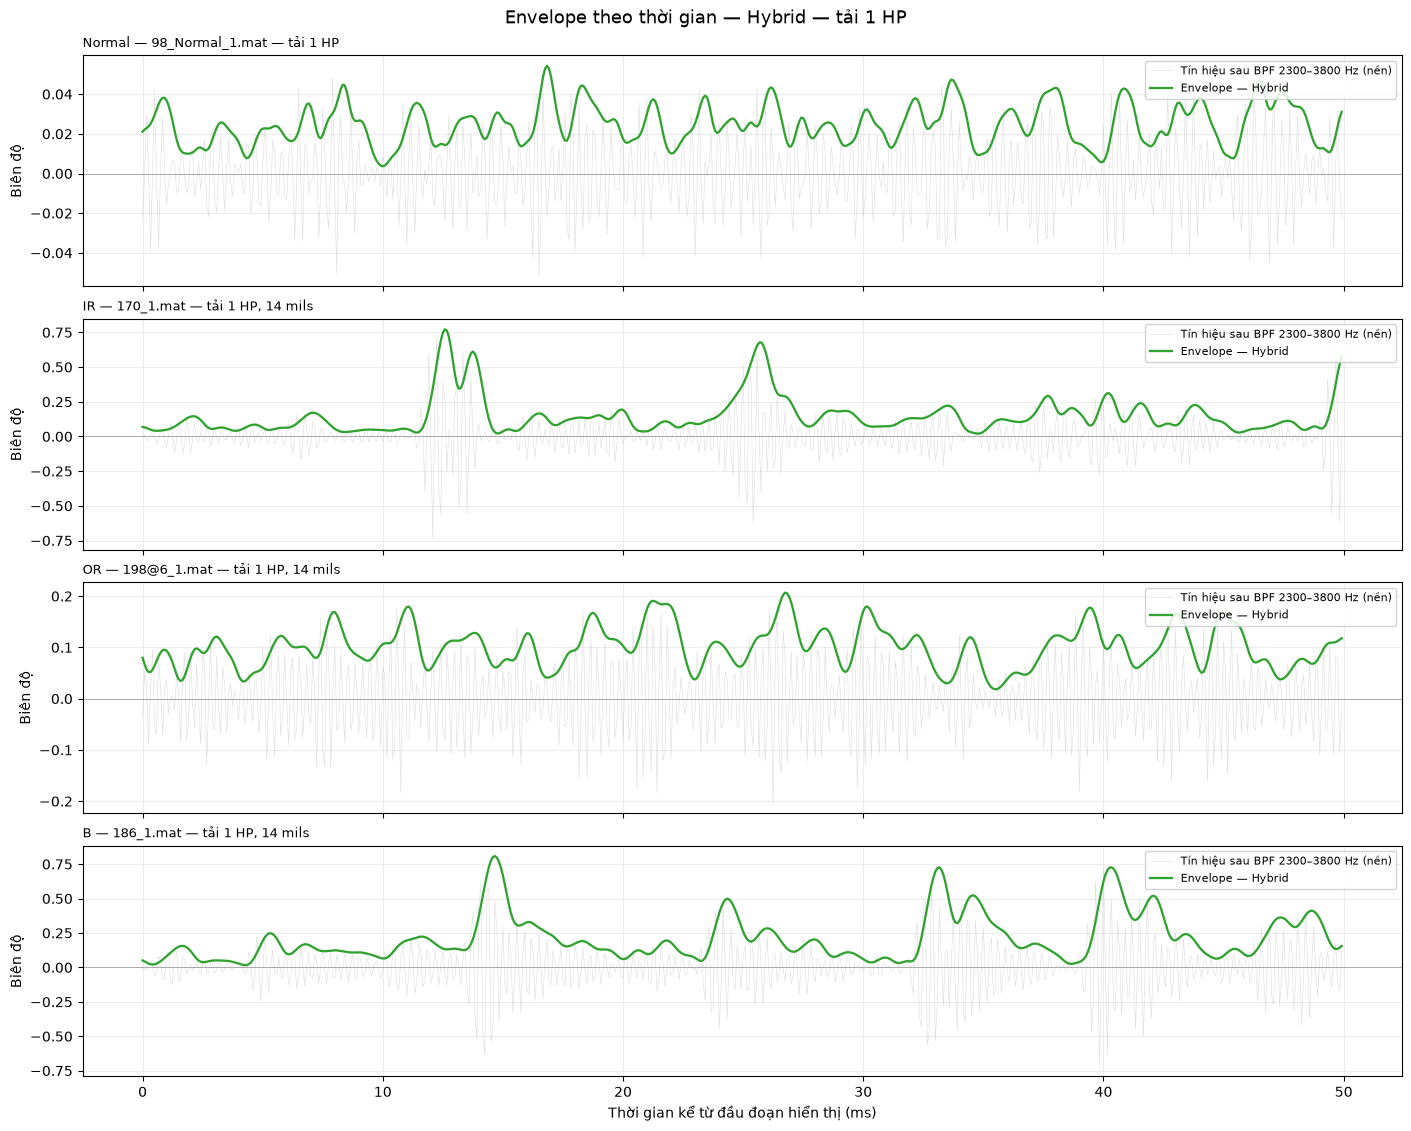

[hybrid] |mean|/std sau warm-up: Normal=2.013, IR=0.915, OR=2.070, B=1.090


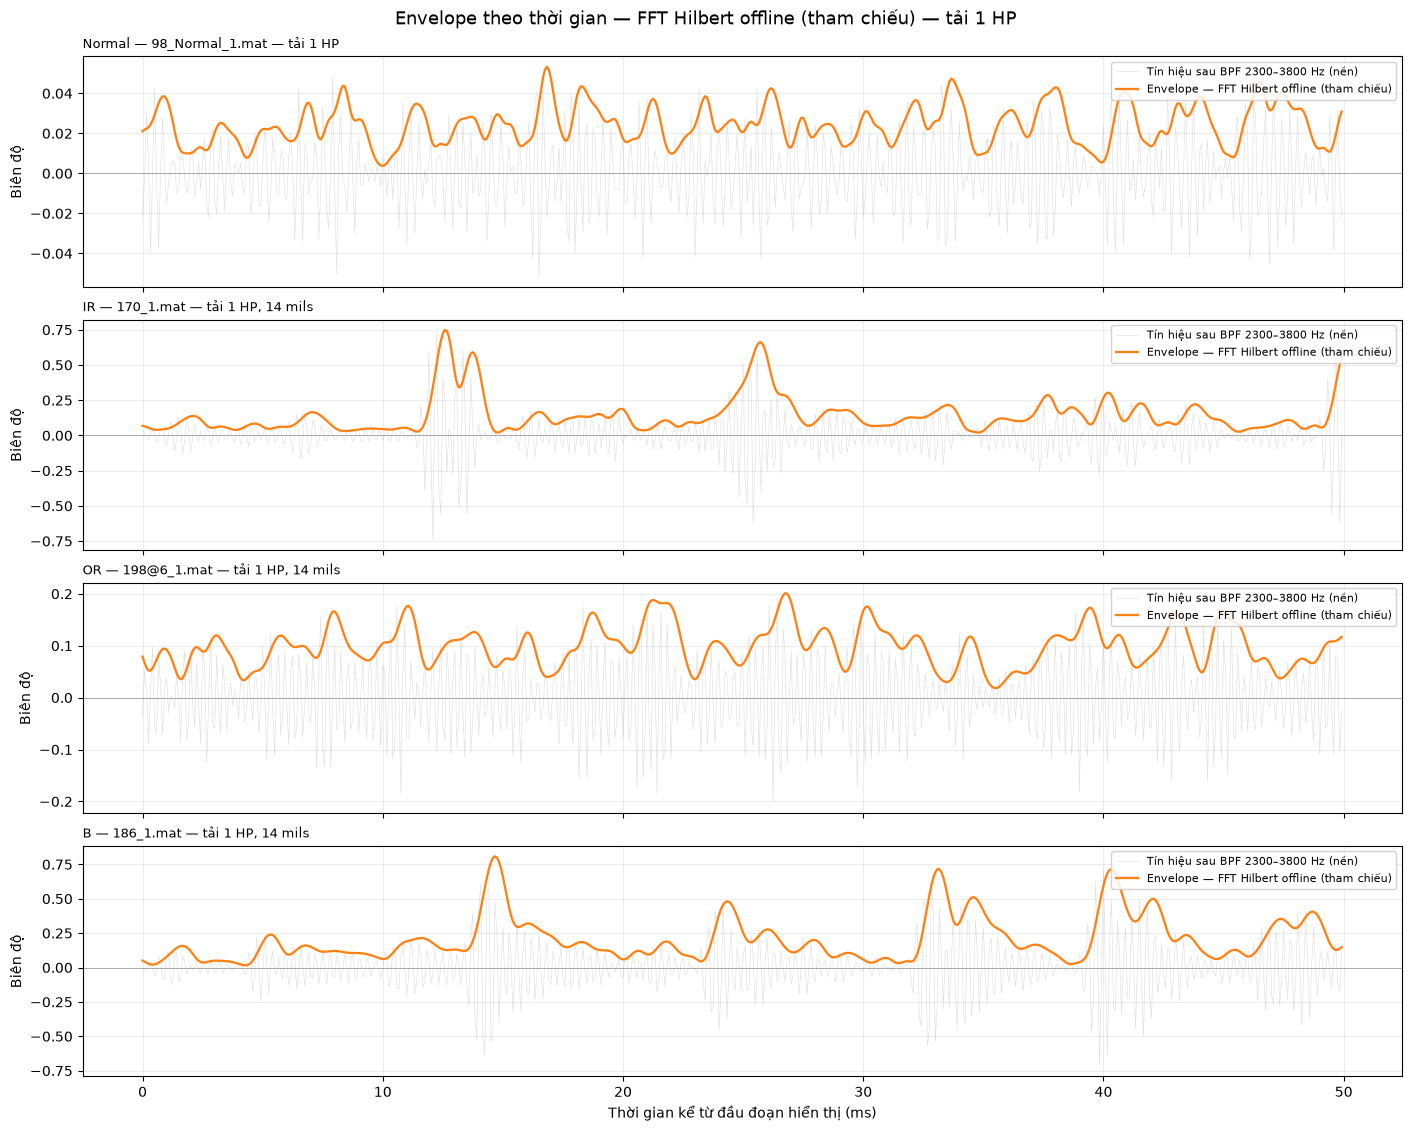

[hilbert_offline] |mean|/std sau warm-up: Normal=2.032, IR=0.915, OR=2.068, B=1.089


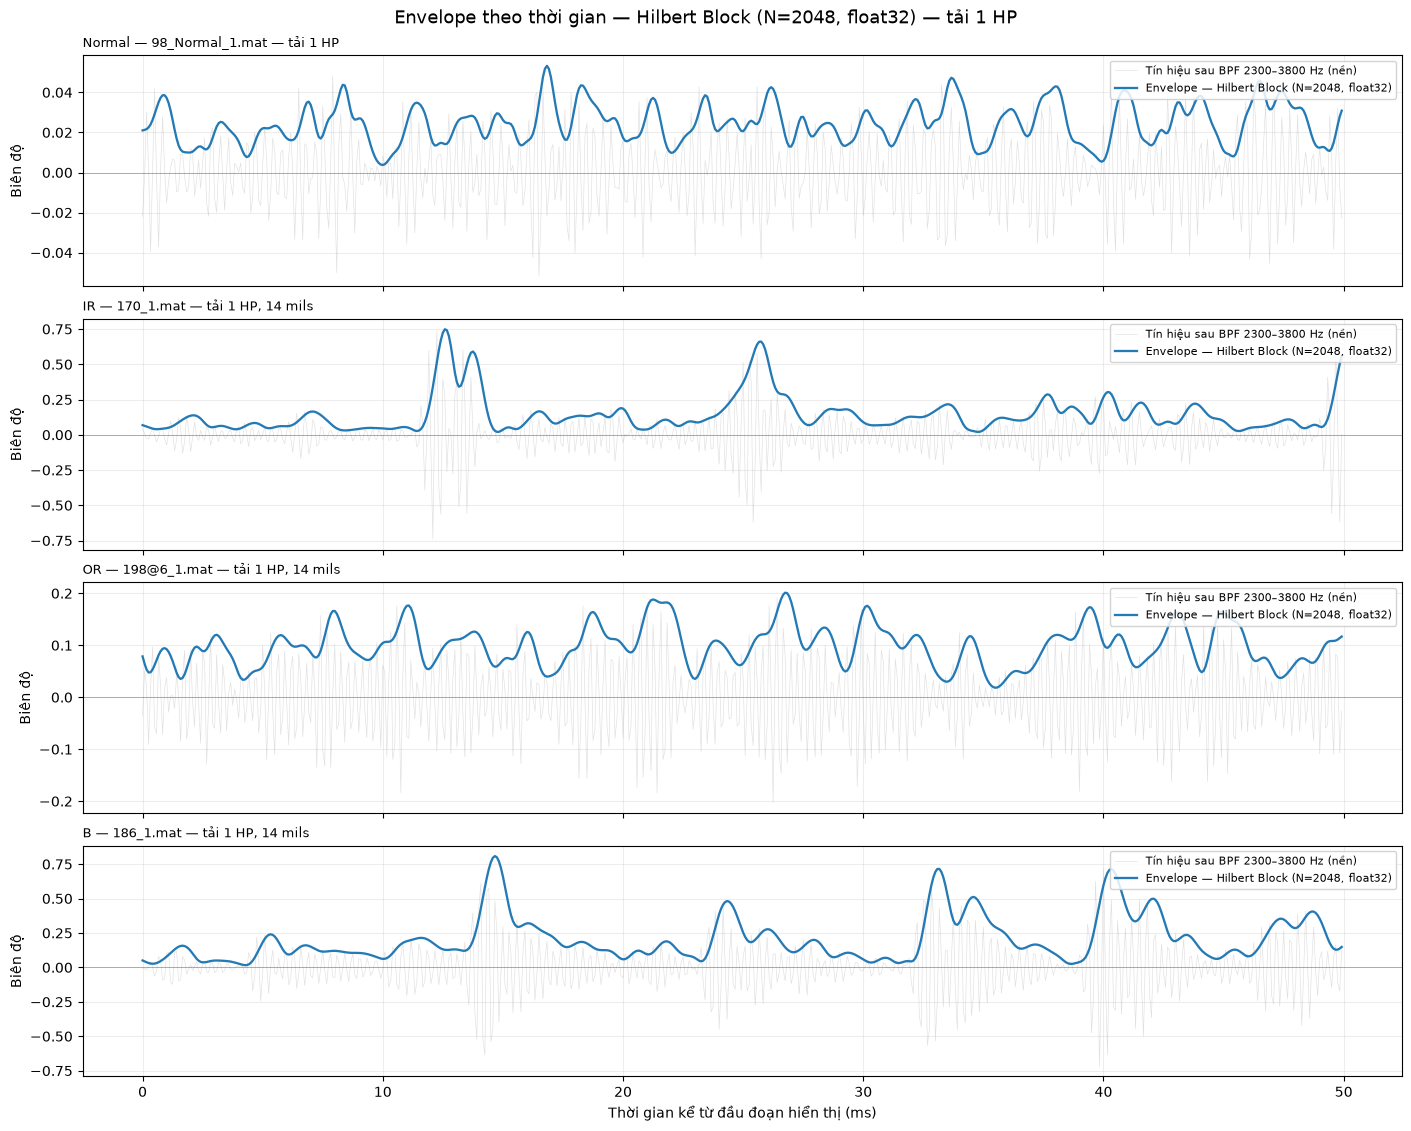

[hilbert_block] |mean|/std sau warm-up: Normal=2.032, IR=0.916, OR=2.068, B=1.089


In [4]:
# Mỗi phương pháp có MỘT FIGURE RIÊNG.
# Tín hiệu sau BPF được giữ ở nền màu xám nhạt; chỉ envelope của method đang xét
# được vẽ nổi bật để tránh các đường envelope che lẫn nhau.

n_plot = int(round(SEGMENT_SECONDS * FS))

for method in ENVELOPE_METHODS:
    key = method["key"]
    name = method["name"]
    color = method["color"]

    fig, axes = plt.subplots(
        len(LABELS_TO_PLOT),
        1,
        figsize=(14, 2.8 * len(LABELS_TO_PLOT)),
        sharex=True,
        constrained_layout=True,
    )
    axes = np.atleast_1d(axes)

    dc_checks = []

    for ax, label in zip(axes, LABELS_TO_PLOT):
        case = CASE_CACHE[label]
        file_path = case["file_path"]
        row = case["row"]
        x_bp = case["x_bp"]
        env = case["envelopes"][key]

        n_valid = min(n_plot, len(env) - WARMUP)
        if n_valid <= 0:
            raise ValueError(f"{Path(file_path).name}: không còn mẫu để vẽ sau warm-up.")

        start = WARMUP
        stop = start + n_valid
        seg = slice(start, stop)
        t_ms = np.arange(n_valid) * 1000.0 / FS

        # Miền thời gian của tín hiệu sau BPF: nền mờ, không cạnh tranh với envelope.
        ax.plot(
            t_ms,
            x_bp[seg],
            color="0.45",
            linewidth=0.45,
            alpha=0.22,
            label=f"Tín hiệu sau BPF {BAND_HZ[0]:g}–{BAND_HZ[1]:g} Hz (nền)",
            zorder=1,
            rasterized=True,
        )

        # Chỉ vẽ envelope của method hiện tại.
        ax.plot(
            t_ms,
            env[seg],
            color=color,
            linewidth=1.65,
            alpha=0.98,
            label=f"Envelope — {name}",
            zorder=3,
        )

        ax.axhline(0.0, color="black", linewidth=0.55, alpha=0.35, zorder=2)
        title = (
            f"{label} — {Path(file_path).name} — tải {LOAD_HP} HP"
            + ("" if label == "Normal" else f", {DIAMETER_MILS} mils")
        )
        ax.set_title(title, loc="left", fontsize=9)
        ax.set_ylabel("Biên độ")
        ax.grid(alpha=0.22)
        ax.legend(loc="upper right", fontsize=8, framealpha=0.85)

        tail = env[WARMUP:]
        dc_ratio = abs(float(np.mean(tail))) / max(float(np.std(tail)), 1e-20)
        dc_checks.append((label, dc_ratio))

    axes[-1].set_xlabel("Thời gian kể từ đầu đoạn hiển thị (ms)")
    fig.suptitle(
        f"Envelope theo thời gian — {name} — tải {LOAD_HP} HP",
        fontsize=13,
    )
    fig.savefig(
        FIGURES_DIR / f"04_envelope_time_{key}_load{LOAD_HP}_{DIAMETER_MILS:03d}mils.png",
        dpi=160,
        bbox_inches="tight",
    )
    plt.show()

    print(
        f"[{key}] |mean|/std sau warm-up: "
        + ", ".join(f"{label}={value:.3f}" for label, value in dc_checks)
    )


### Phổ envelope (envelope spectrum)

Mỗi phương pháp envelope được vẽ trong **một figure riêng**, không chồng phổ của các phương pháp lên nhau.

Phổ được tính trên toàn bộ envelope sau warm-up (không chia cửa sổ 2048 mẫu), dùng cửa sổ Hann chỉ để quan sát và giảm rò rỉ phổ. Các đường đứng thể hiện BPFO, BPFI, BSF và hài 1–3 tính từ RPM trong manifest; thành phần lỗi tương ứng với nhãn được làm nổi bật.


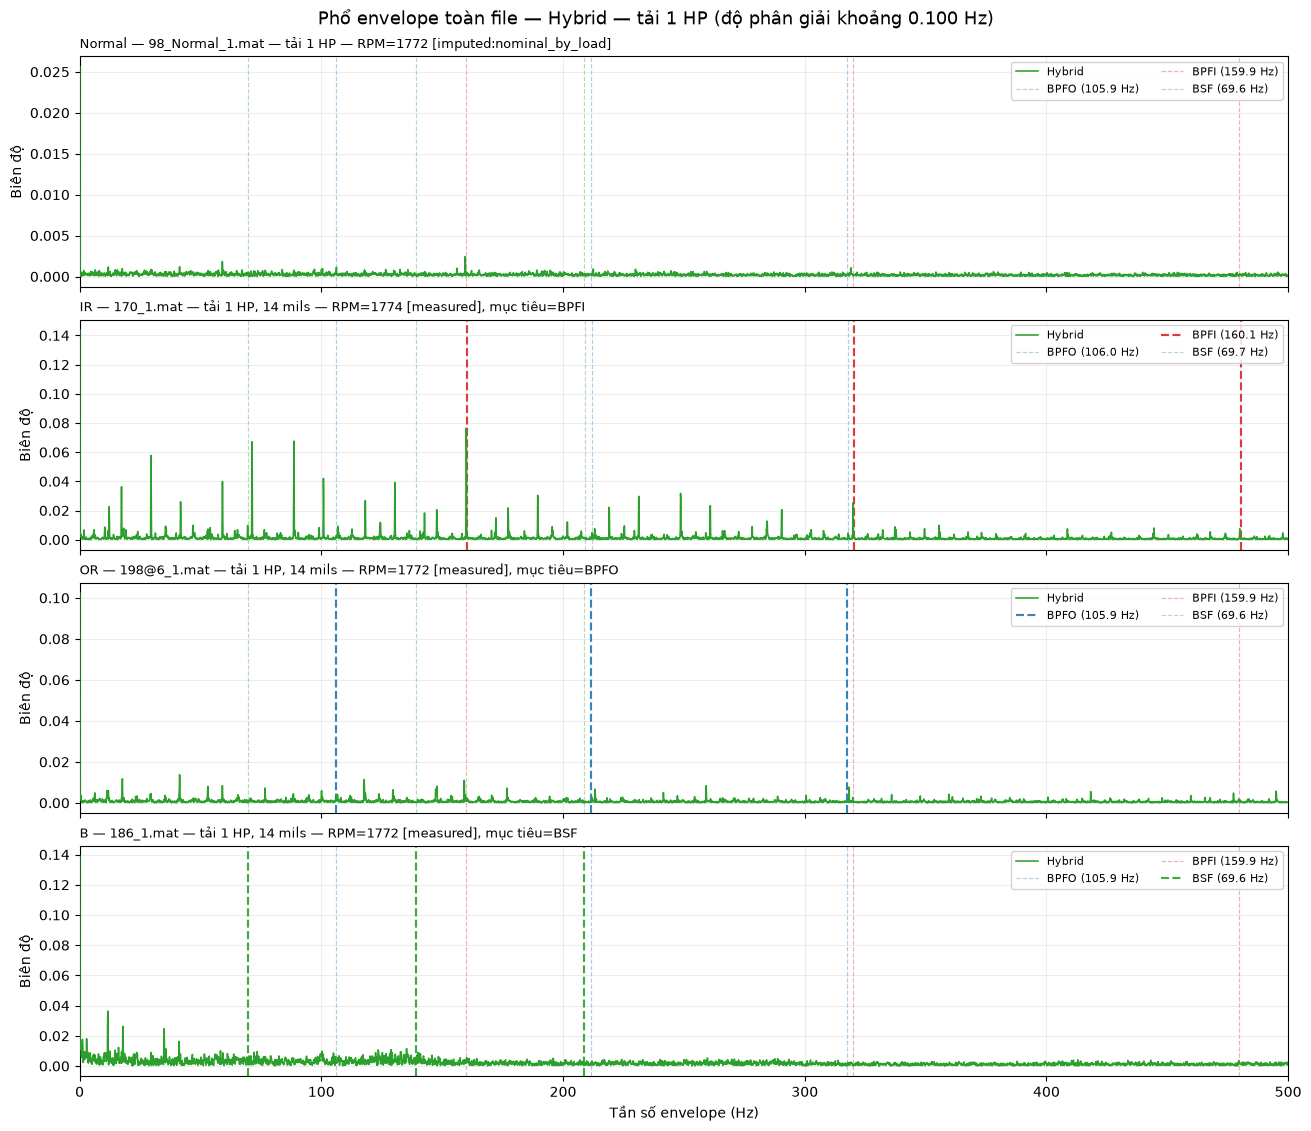

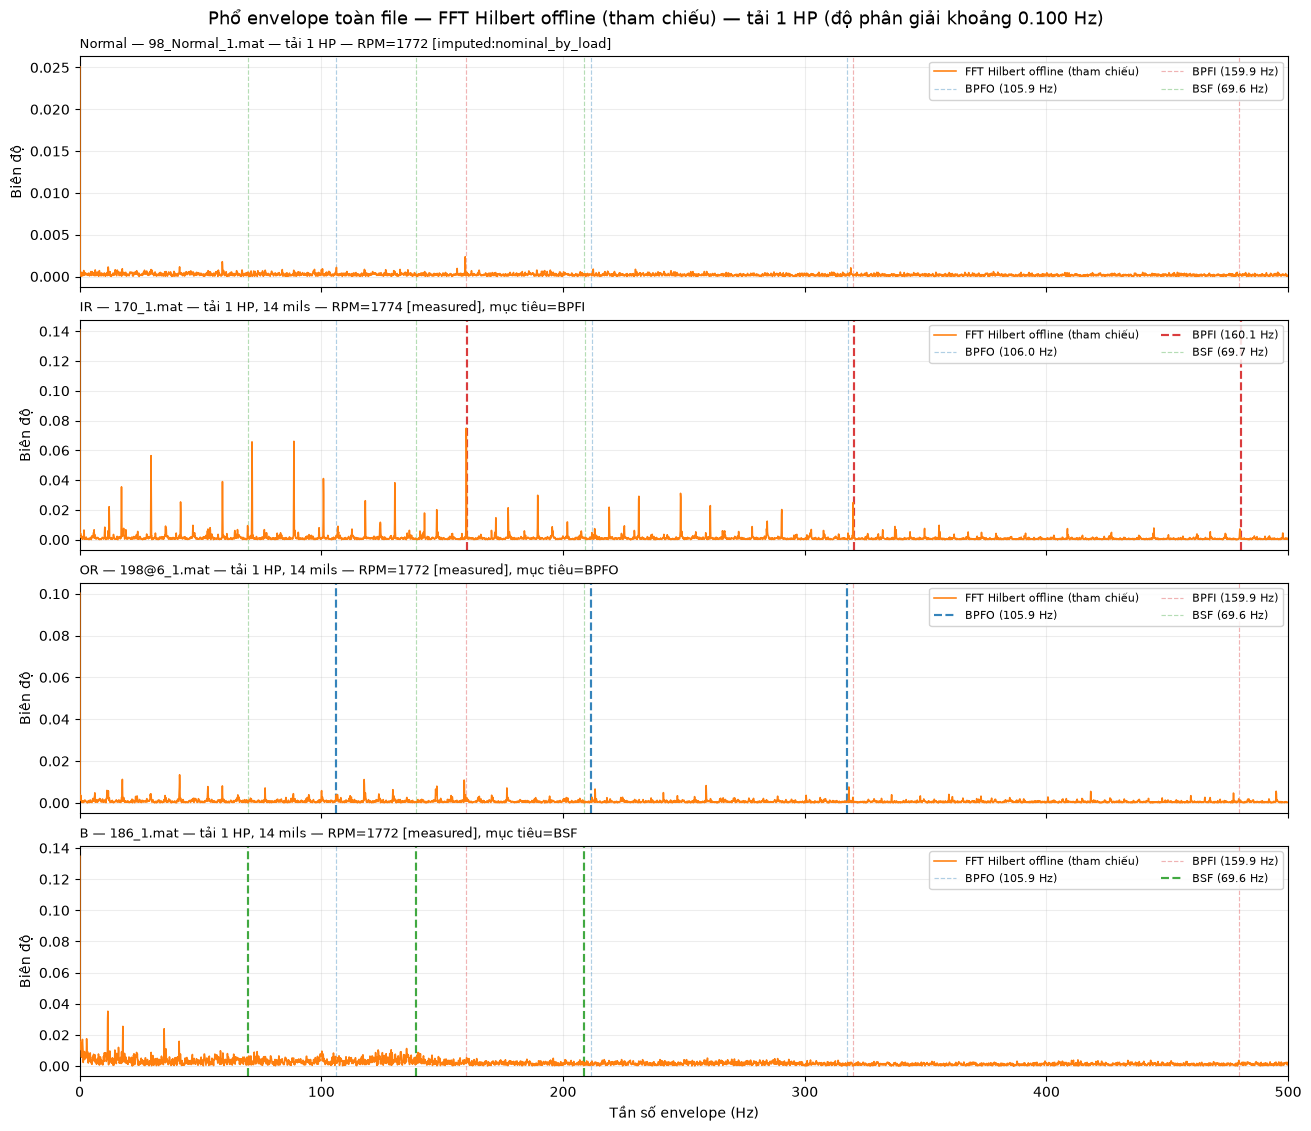

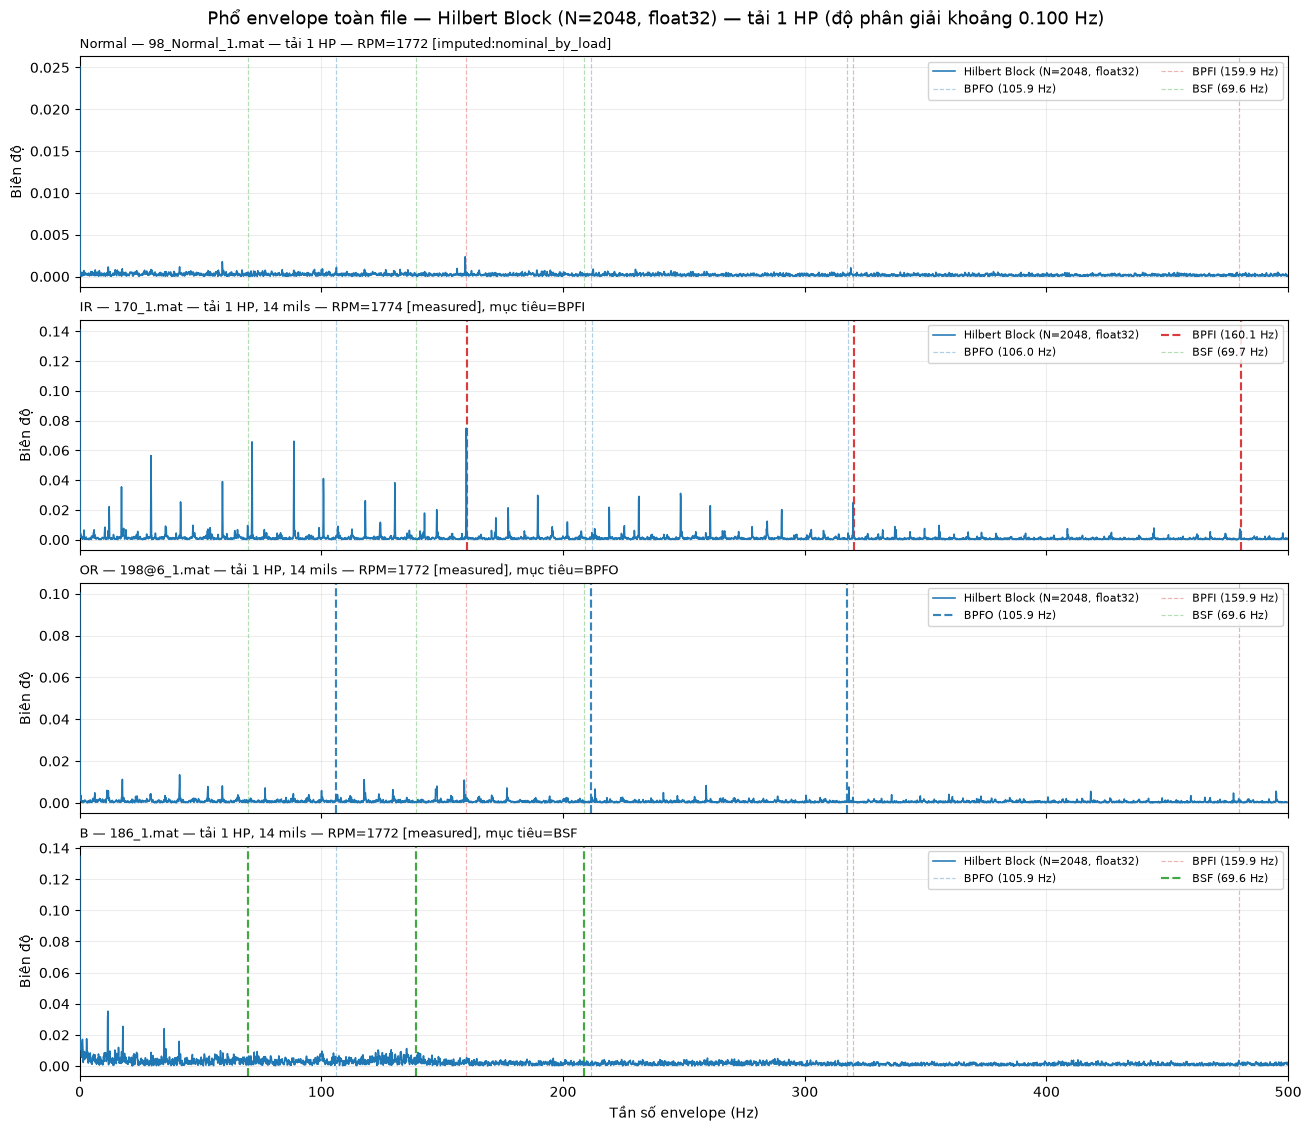

In [5]:
SPECTRUM_LABELS = LABELS_TO_PLOT
SPECTRUM_FMAX_HZ = 500.0
LOG_Y = False
APPLY_WINDOW = True             # chỉ dùng cho hình phổ, không thay đổi feature MLP
FAULT_KEY_BY_LABEL = {"IR": "BPFI", "OR": "BPFO", "B": "BSF"}
FAULT_LINE_COLOR = {
    "BPFO": "tab:blue",
    "BPFI": "tab:red",
    "BSF": "tab:green",
}
ENV_TARGETS = ("BPFO", "BPFI", "BSF")  # envelope không dùng f_rot


def full_envelope_spectrum(env):
    """Phổ envelope toàn file sau warm-up; DC đã được xử lý trong dsp.py."""
    segment = np.asarray(env, dtype=np.float64)[WARMUP:]
    if segment.size < 8:
        raise ValueError("Đoạn envelope sau warm-up quá ngắn để tính phổ.")
    return dsp.compute_fft(segment, FS, apply_window=APPLY_WINDOW)


# Một figure riêng cho từng method; mỗi figure có một subplot cho từng label.
for method in ENVELOPE_METHODS:
    key = method["key"]
    name = method["name"]
    color = method["color"]

    fig, axes = plt.subplots(
        len(SPECTRUM_LABELS),
        1,
        figsize=(13, 2.8 * len(SPECTRUM_LABELS)),
        sharex=True,
        constrained_layout=True,
    )
    axes = np.atleast_1d(axes)
    resolutions = []

    for ax, label in zip(axes, SPECTRUM_LABELS):
        case = CASE_CACHE[label]
        file_path = case["file_path"]
        row = case["row"]
        rpm = float(row["rpm"])
        rpm_source = str(row.get("rpm_source", "unknown"))
        fault_hz = cfg.bearing_fault_frequencies(rpm)
        target_key = FAULT_KEY_BY_LABEL.get(label)

        freqs, mag = full_envelope_spectrum(case["envelopes"][key])
        resolutions.append(float(freqs[1] - freqs[0]))
        mask = (freqs > 0) & (freqs <= SPECTRUM_FMAX_HZ)

        ax.plot(
            freqs[mask],
            mag[mask],
            color=color,
            linewidth=1.15,
            label=f"{name}",
            zorder=3,
        )

        for fkey in ENV_TARGETS:
            is_target = fkey == target_key
            for harmonic in (1, 2, 3):
                target_hz = fault_hz[fkey] * harmonic
                ax.axvline(
                    target_hz,
                    color=FAULT_LINE_COLOR[fkey],
                    linestyle="--",
                    linewidth=1.55 if is_target else 0.85,
                    alpha=0.9 if is_target else 0.35,
                    label=f"{fkey} ({fault_hz[fkey]:.1f} Hz)" if harmonic == 1 else None,
                    zorder=2,
                )

        if LOG_Y:
            ax.set_yscale("log")
        ax.set_ylabel("Biên độ" + (" (log)" if LOG_Y else ""))
        title = (
            f"{label} — {Path(file_path).name} — tải {LOAD_HP} HP"
            + ("" if label == "Normal" else f", {DIAMETER_MILS} mils")
            + f" — RPM={rpm:g} [{rpm_source}]"
            + (f", mục tiêu={target_key}" if target_key else "")
        )
        ax.set_title(title, loc="left", fontsize=9)
        ax.grid(alpha=0.22)
        ax.legend(loc="upper right", fontsize=8, ncol=2, framealpha=0.85)

    axes[-1].set_xlabel("Tần số envelope (Hz)")
    axes[-1].set_xlim(0, SPECTRUM_FMAX_HZ)
    fig.suptitle(
        f"Phổ envelope toàn file — {name} — tải {LOAD_HP} HP "
        f"(độ phân giải khoảng {np.mean(resolutions):.3f} Hz)",
        fontsize=13,
    )
    fig.savefig(
        FIGURES_DIR / f"04_envelope_spectrum_{key}_load{LOAD_HP}_{DIAMETER_MILS:03d}mils.png",
        dpi=160,
        bbox_inches="tight",
    )
    plt.show()


### Đặc trưng envelope của mô hình (đối chiếu)

Các hình phổ phía trên dùng toàn file để quan sát tần số lỗi. Đặc trưng MLP lại được tính trên **từng cửa sổ raw 2048 mẫu**; envelope được giảm mẫu ×2 thành 1024 mẫu ở \(f_{s,env}=6\,kHz\). Bảng dưới đối chiếu 7 đặc trưng envelope của cửa sổ đầu tiên sau warm-up giữa các phương pháp. Cấu hình này chỉ để kiểm tra trực quan, không thay cho bảng feature đầy đủ ở notebook 05.


In [6]:
from src.order import extract_order_features

WINDOW_RAW = int(cfg.WINDOW_SIZE_RAW)
STRIDE_RAW = int(cfg.STRIDE_RAW)


def first_envelope_window(env_full):
    env_dec, fs_env = dsp.decimate_envelope(
        env_full,
        FS,
        factor=dsp.ENV_DECIM,
        lp_cutoff=LP_CUTOFF_HZ,
    )
    n_env = WINDOW_RAW // dsp.ENV_DECIM

    for start in range(0, len(env_full) - WINDOW_RAW + 1, STRIDE_RAW):
        if start >= WARMUP:
            start_env = start // dsp.ENV_DECIM
            window = env_dec[start_env:start_env + n_env]
            if len(window) != n_env:
                raise ValueError("Cửa sổ envelope đầu tiên không đủ 1024 mẫu.")
            return window, fs_env

    raise ValueError("Không có cửa sổ envelope nào sau warm-up.")


feature_rows = []
for label in SPECTRUM_LABELS:
    case = CASE_CACHE[label]
    rpm = float(case["row"]["rpm"])

    for method in ENVELOPE_METHODS:
        key = method["key"]
        env_window, fs_env = first_envelope_window(case["envelopes"][key])
        freqs, magnitude = dsp.compute_fft(env_window, fs_env)

        features = extract_order_features(
            freqs,
            magnitude,
            rpm,
            target_names=ENV_TARGETS,
            prefix="envelope",
        )
        feature_rows.append({
            "label": label,
            "method": key,
            **features,
        })

envelope_feature_table = (
    pd.DataFrame(feature_rows)
    .set_index(["label", "method"])
    .sort_index()
)
display(envelope_feature_table.round(4))


envelope_BSF_h1  envelope_BPFO_h1  envelope_BSF_h2  \
label  method                                                                
B      hilbert_block             0.0135            0.0532           0.0524   
       hilbert_offline           0.0135            0.0532           0.0524   
       hybrid                    0.0135            0.0544           0.0542   
IR     hilbert_block             0.0738            0.0281           0.0137   
       hilbert_offline           0.0738            0.0281           0.0137   
       hybrid                    0.0755            0.0287           0.0139   
Normal hilbert_block             0.0012            0.0005           0.0015   
       hilbert_offline           0.0012            0.0005           0.0015   
       hybrid                    0.0013            0.0006           0.0014   
OR     hilbert_block             0.0151            0.0066           0.0025   
       hilbert_offline           0.0151            0.0066           0.0025   
       hybrid                    0.0154            0.0068           0.0026   

                        envelope_BPFI_h1  envelope_BPFO_h2_and_BSF_h3  \
label  method                                                           
B      hilbert_block              0.0432                       0.0353   
       hilbert_offline            0.0432                       0.0352   
       hybrid                     0.0446                       0.0361   
IR     hilbert_block              0.0709                       0.0126   
       hilbert_offline            0.0709                       0.0126   
       hybrid                     0.0723                       0.0128   
Normal hilbert_block              0.0027                       0.0013   
       hilbert_offline            0.0027                       0.0013   
       hybrid                     0.0027                       0.0013   
OR     hilbert_block              0.0117                       0.0062   
       hilbert_offline            0.0117                       0.0062   
       hybrid                     0.0118                       0.0061   

                        envelope_BPFO_h3_and_BPFI_h2  envelope_BPFI_h3  
label  method                                                           
B      hilbert_block                          0.0145            0.0176  
       hilbert_offline                        0.0145            0.0175  
       hybrid                                 0.0148            0.0182  
IR     hilbert_block                          0.0209            0.0095  
       hilbert_offline                        0.0209            0.0096  
       hybrid                                 0.0212            0.0103  
Normal hilbert_block                          0.0018            0.0024  
       hilbert_offline                        0.0018            0.0024  
       hybrid                                 0.0018            0.0023  
OR     hilbert_block                          0.0008            0.0076  
       hilbert_offline                        0.0008            0.0076  
       hybrid                                 0.0009            0.0078